<a href="https://colab.research.google.com/github/GH-Rumi/PCVK26_7_HelmiRR/blob/main/Week05_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Helmi Rizqi Ramadhan'
NIM  = '244107020107'

N     = int(107)
PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L' : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Helmi Rizqi Ramadhan
NIM    : 244107020107 | N = 107
bins   : 64
clip   : 2.0
tile   : 5
L      : 8
WAKTU  : 2026-09-27 22:36:22 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : e81dab593743ebf5


In [18]:
BASE = f'/content/drive/MyDrive/PCVK 2026/Images/' + NIM
CONTOH = '/content/drive/MyDrive/PCVK 2026/Images'

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

In [11]:
def set_title():
    plt.title(NIM + ' - CLAHE clip ' + str(PARAM['clip']), fontsize=9)

# **Percobaan Praktikum**

<BarContainer object of 256 artists>

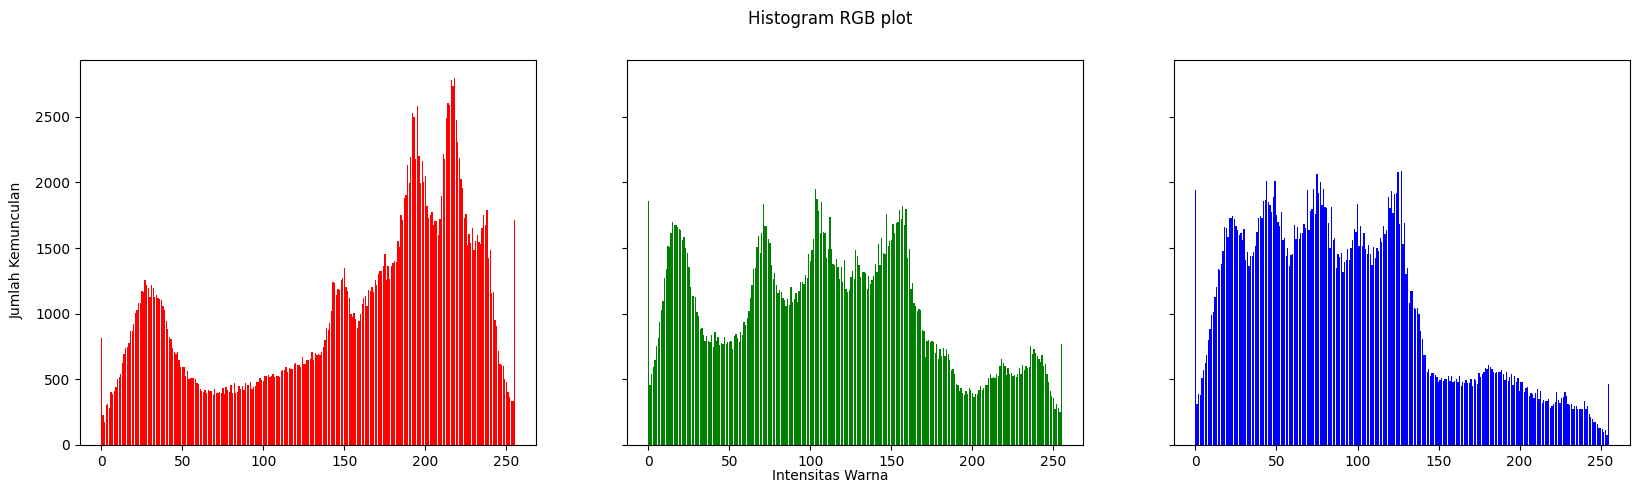

In [8]:
#membuat histogram image (manual)
img = cv.imread('/content/drive/MyDrive/PCVK 2026/Images/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0,height) :
  for x in range(0,width) :
    red[img[y][x][0]] += 1
    green[img[y][x][1]] += 1
    blue[img[y][x][2]] += 1


names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

# **Pertanyaan Praktikum E-1**
# No 1


--- Pembuktian pada: /content/drive/MyDrive/PCVK 2026/Images/244107020107/KTM1b ---
Selisih maksimal Manual vs NumPy : 0
Selisih maksimal Manual vs OpenCV: 0.0


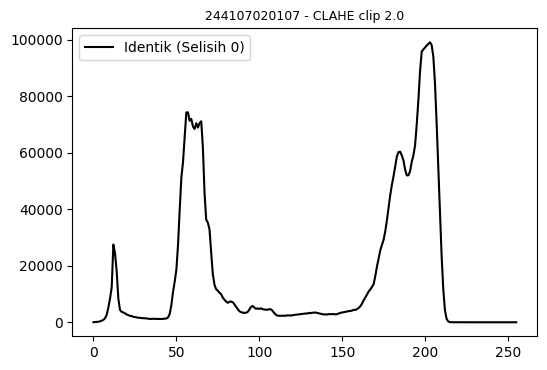

In [26]:
uji_coba = [f'{BASE}/KTM1b']

for path in uji_coba:
    img_gray = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if img_gray is not None:
        print(f"\n--- Pembuktian pada: {path} ---")

        L = 256
        hist_manual = np.zeros(L, dtype=np.int64)
        for y in range(img_gray.shape[0]):
            for x in range(img_gray.shape[1]):
                hist_manual[img_gray[y, x]] += 1
        # ------------------------------------------------

        hist_np, _ = np.histogram(img_gray.ravel(), bins=256, range=[0, 256])
        hist_cv = cv.calcHist([img_gray], [0], None, [256], [0, 256]).ravel()

        diff_np = np.max(np.abs(hist_manual - hist_np))
        diff_cv = np.max(np.abs(hist_manual - hist_cv))

        print("Selisih maksimal Manual vs NumPy :", diff_np)
        print("Selisih maksimal Manual vs OpenCV:", diff_cv)

        plt.figure(figsize=(6,4))
        plt.plot(hist_manual, color='black', label='Identik (Selisih 0)')

        set_title()

        plt.legend()
        plt.show()
    else:
        print(f"Gambar tidak ditemukan: {path}")

# No 2

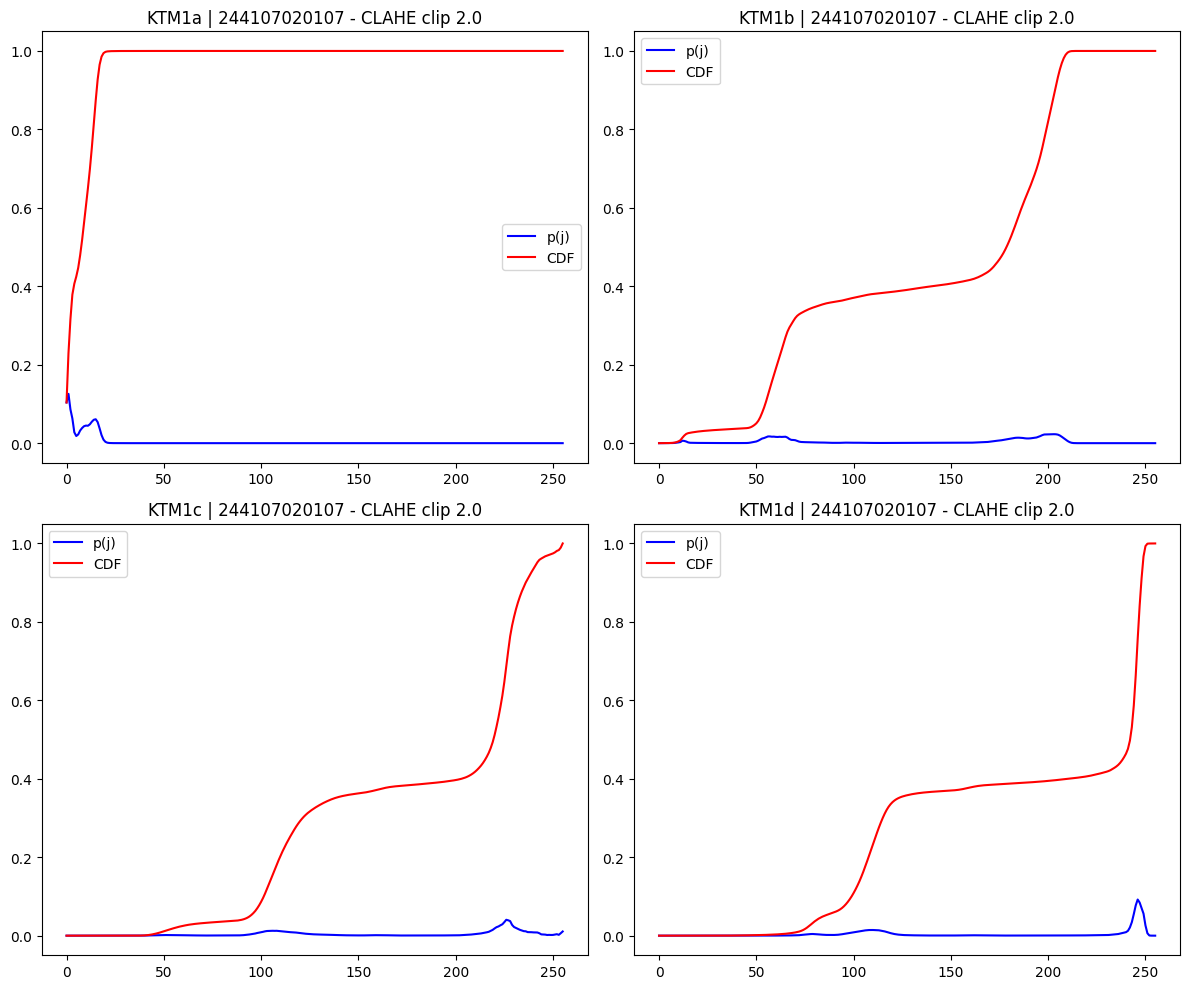

In [33]:
daftar_KTM = ['KTM1a', 'KTM1b', 'KTM1c', 'KTM1d']
plt.figure(figsize=(12, 10))

for i, nama_file in enumerate(daftar_KTM):
    path_file = f'{BASE}/{nama_file}'
    citra_abu = cv.imread(path_file, cv.IMREAD_GRAYSCALE)

    if citra_abu is not None:
        # --- Perhitungan Histogram Manual (Tanpa def) ---
        rentang_L = 256
        hist_inline = np.zeros(rentang_L, dtype=np.int64)
        for y in range(citra_abu.shape[0]):
            for x in range(citra_abu.shape[1]):
                hist_inline[citra_abu[y, x]] += 1
        # ------------------------------------------------

        probabilitas = hist_inline / citra_abu.size  # Normalisasi p(j)
        dist_kumulatif = np.cumsum(probabilitas)     # Distribusi kumulatif (CDF)

        plt.subplot(2, 2, i+1)
        plt.plot(probabilitas, label='p(j)', color='blue')
        plt.plot(dist_kumulatif, label='CDF', color='red')

        plt.title(f"{nama_file} | {NIM}" + ' - CLAHE clip ' + str(PARAM['clip']))

        plt.legend()
    else:
        print(f"File {nama_file} tidak ditemukan di path: {path_file}")

plt.tight_layout()
plt.show()

# No 3

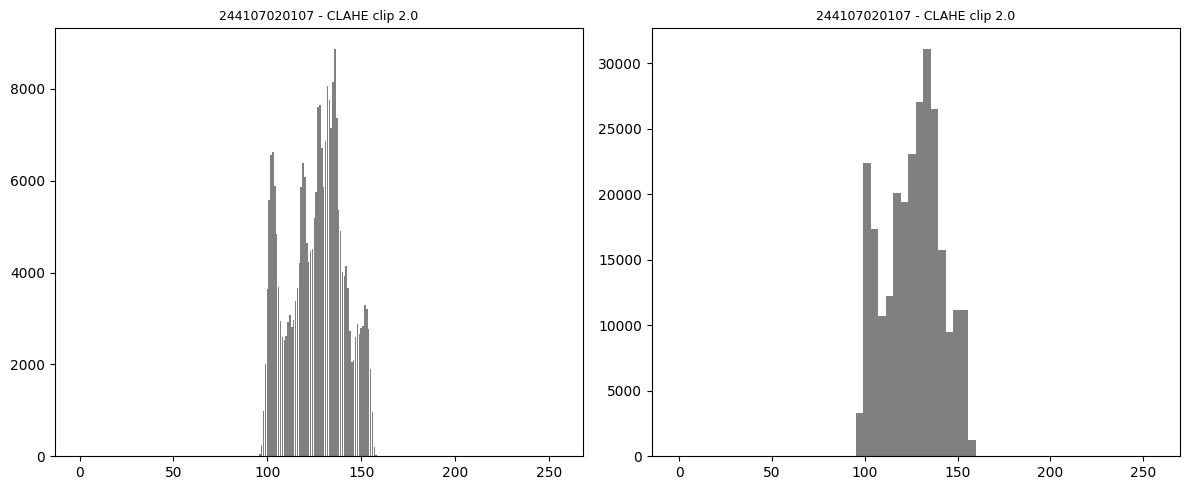

In [34]:
citra_lena = cv.imread(f'{CONTOH}/lena_lc.jpg', cv.IMREAD_GRAYSCALE)

if citra_lena is not None:
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    hist_penuh, _ = np.histogram(citra_lena.ravel(), bins=256, range=[0, 256])
    plt.bar(np.arange(256), hist_penuh, color='gray')

    set_title()

    plt.subplot(1, 2, 2)
    jumlah_bins = PARAM['bins']
    hist_dinamis, _ = np.histogram(citra_lena.ravel(), bins=jumlah_bins, range=[0, 256])
    plt.bar(np.linspace(0, 255, jumlah_bins), hist_dinamis, width=256/jumlah_bins, color='gray')

    set_title()

    plt.tight_layout()
    plt.show()
else:
    print("Gambar lena_lc.jpg tidak ditemukan. Periksa kembali path direktori CONTOH Anda.")

Ketika jumlah bin pada histogram dikurangi (misalnya dari 256 menjadi 64, 32, atau lebih kecil), terjadi pengelompokan (grouping) beberapa nilai intensitas yang berdekatan ke dalam satu keranjang (bin) yang sama.

# **Percobaan Praktikum E-2**

In [35]:
def ekualisasi_kanal_manual(kanal_warna):
    hist_kanal, _ = np.histogram(kanal_warna.ravel(), bins=256, range=[0, 256])

    dist_kumulatif = hist_kanal.cumsum()

    cdf_normalisasi = dist_kumulatif / dist_kumulatif.max()

    nilai_pemetaan = np.round(cdf_normalisasi * 255).astype(np.uint8)

    return nilai_pemetaan[kanal_warna]

In [36]:
def visualisasi_he_rgb(path_gambar, nama_gambar):
    citra_bgr = cv.imread(path_gambar)
    if citra_bgr is None:
        print(f"Peringatan: Berkas {nama_gambar} tidak ditemukan di path {path_gambar}")
        return

    citra_rgb = cv.cvtColor(citra_bgr, cv.COLOR_BGR2RGB)

    kanal_r, kanal_g, kanal_b = cv.split(citra_rgb)

    r_he = ekualisasi_kanal_manual(kanal_r)
    g_he = ekualisasi_kanal_manual(kanal_g)
    b_he = ekualisasi_kanal_manual(kanal_b)

    h_r_asli, _ = np.histogram(kanal_r.ravel(), bins=256, range=[0, 256])
    h_g_asli, _ = np.histogram(kanal_g.ravel(), bins=256, range=[0, 256])
    h_b_asli, _ = np.histogram(kanal_b.ravel(), bins=256, range=[0, 256])

    h_r_he, _ = np.histogram(r_he.ravel(), bins=256, range=[0, 256])
    h_g_he, _ = np.histogram(g_he.ravel(), bins=256, range=[0, 256])
    h_b_he, _ = np.histogram(b_he.ravel(), bins=256, range=[0, 256])

--- TAHAP 1: Memproses citra referensi (lena_lc.jpg) ---


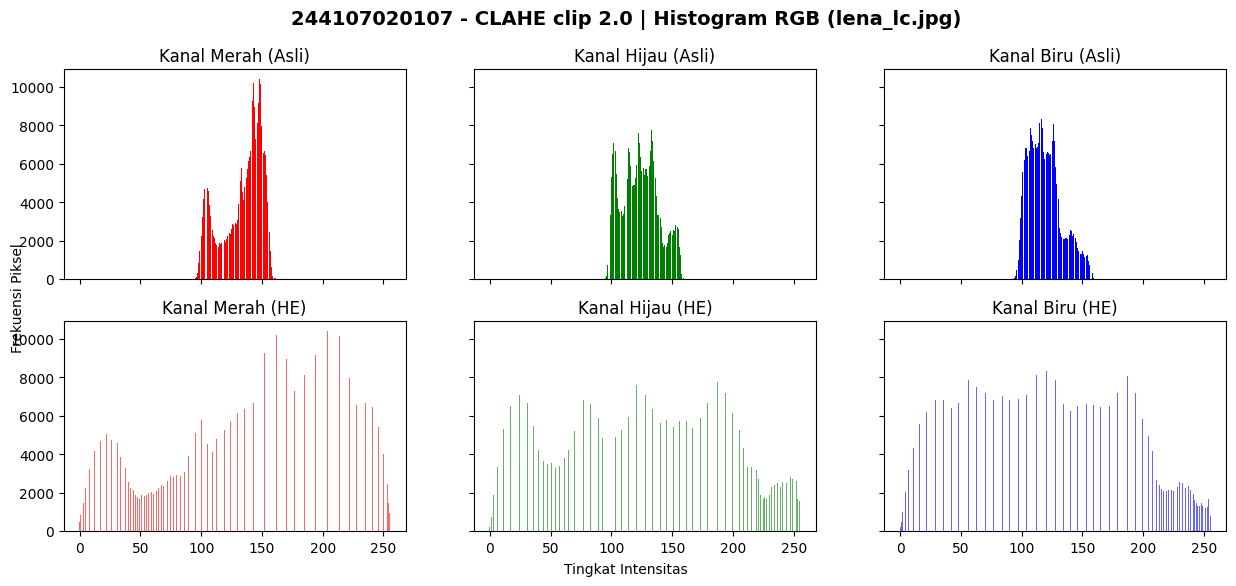

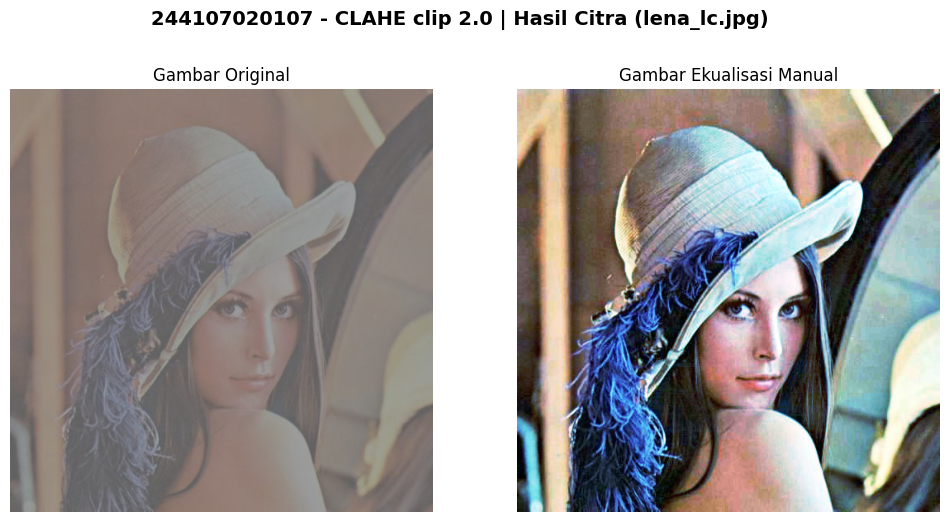

In [47]:
# Fungsi Ekualisasi Histogram Manual untuk Satu Kanal Warna
def ekualisasi_kanal_manual(kanal_warna):
    hist_kanal, _ = np.histogram(kanal_warna.ravel(), bins=256, range=[0, 256])

    dist_kumulatif = hist_kanal.cumsum()

    cdf_normalisasi = dist_kumulatif / dist_kumulatif.max()

    nilai_pemetaan = np.round(cdf_normalisasi * 255).astype(np.uint8)

    return nilai_pemetaan[kanal_warna]

# Fungsi Utama untuk Memproses dan Memvisualisasikan HE pada RGB
def visualisasi_he_rgb(path_gambar, nama_gambar):
    citra_bgr = cv.imread(path_gambar)
    if citra_bgr is None:
        print(f"Peringatan: Berkas {nama_gambar} tidak ditemukan di path {path_gambar}")
        return

    citra_rgb = cv.cvtColor(citra_bgr, cv.COLOR_BGR2RGB)

    kanal_r, kanal_g, kanal_b = cv.split(citra_rgb)

    r_he = ekualisasi_kanal_manual(kanal_r)
    g_he = ekualisasi_kanal_manual(kanal_g)
    b_he = ekualisasi_kanal_manual(kanal_b)

    h_r_asli, _ = np.histogram(kanal_r.ravel(), bins=256, range=[0, 256])
    h_g_asli, _ = np.histogram(kanal_g.ravel(), bins=256, range=[0, 256])
    h_b_asli, _ = np.histogram(kanal_b.ravel(), bins=256, range=[0, 256])

    h_r_he, _ = np.histogram(r_he.ravel(), bins=256, range=[0, 256])
    h_g_he, _ = np.histogram(g_he.ravel(), bins=256, range=[0, 256])
    h_b_he, _ = np.histogram(b_he.ravel(), bins=256, range=[0, 256])

    # VISUALISASI 1: GRAFIK HISTOGRAM RGB (ASLI VS HE)
    sumbu_x = np.arange(256)
    fig, axs = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey=True)

    fig.suptitle(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + f' | Histogram RGB ({nama_gambar})', fontsize=14, fontweight='bold')

    fig.text(0.09, 0.5, 'Frekuensi Piksel', va='center', rotation='vertical')
    fig.text(0.5, 0.04, 'Tingkat Intensitas', ha='center')

    axs[0, 0].bar(sumbu_x, h_r_asli, color='red'); axs[0, 0].set_title('Kanal Merah (Asli)')
    axs[0, 1].bar(sumbu_x, h_g_asli, color='green'); axs[0, 1].set_title('Kanal Hijau (Asli)')
    axs[0, 2].bar(sumbu_x, h_b_asli, color='blue'); axs[0, 2].set_title('Kanal Biru (Asli)')

    axs[1, 0].bar(sumbu_x, h_r_he, color='red', alpha=0.6); axs[1, 0].set_title('Kanal Merah (HE)')
    axs[1, 1].bar(sumbu_x, h_g_he, color='green', alpha=0.6); axs[1, 1].set_title('Kanal Hijau (HE)')
    axs[1, 2].bar(sumbu_x, h_b_he, color='blue', alpha=0.6); axs[1, 2].set_title('Kanal Biru (HE)')

    plt.show()

    # VISUALISASI 2: PERBANDINGAN FOTO (ASLI VS HE)
    citra_he_rgb = cv.merge([r_he, g_he, b_he])

    fig2, ax2 = plt.subplots(1, 2, figsize=(12, 6))

    fig2.suptitle(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + f' | Hasil Citra ({nama_gambar})', fontsize=14, fontweight='bold')

    ax2[0].imshow(citra_rgb)
    ax2[0].set_title('Gambar Original')
    ax2[0].axis('off')

    ax2[1].imshow(citra_he_rgb)
    ax2[1].set_title('Gambar Ekualisasi Manual')
    ax2[1].axis('off')

    plt.show()

# EKSEKUSI TAHAP 1
print("--- TAHAP 1: Memproses citra referensi (lena_lc.jpg) ---")
visualisasi_he_rgb(f'{CONTOH}/lena_lc.jpg', 'lena_lc.jpg')


--- TAHAP 2: Memproses citra pribadi (KTM1a) ---


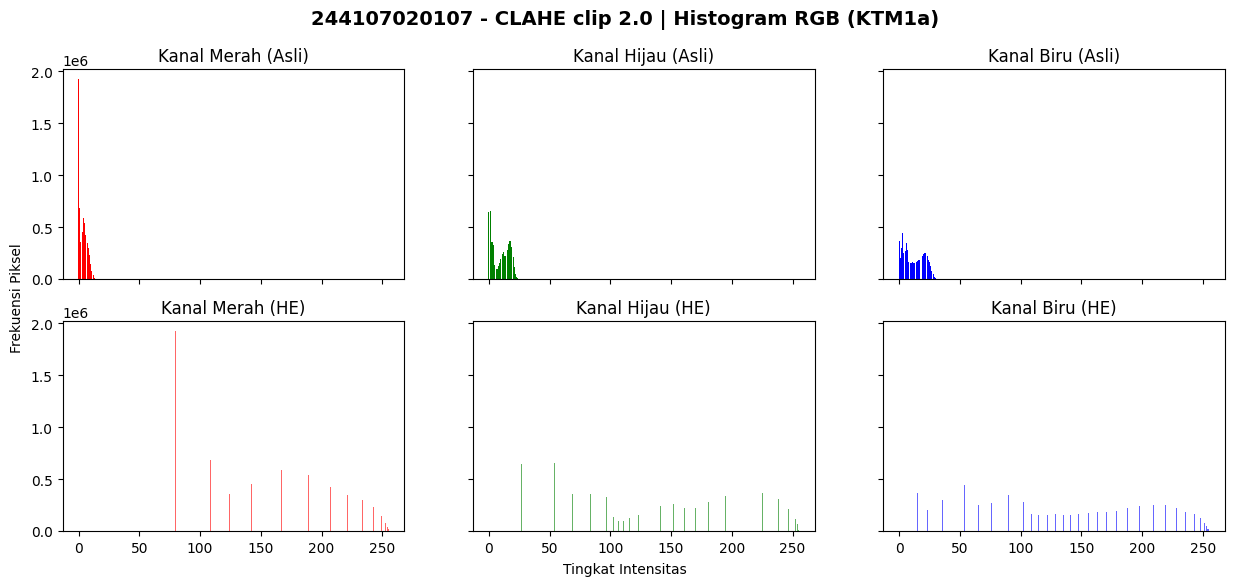

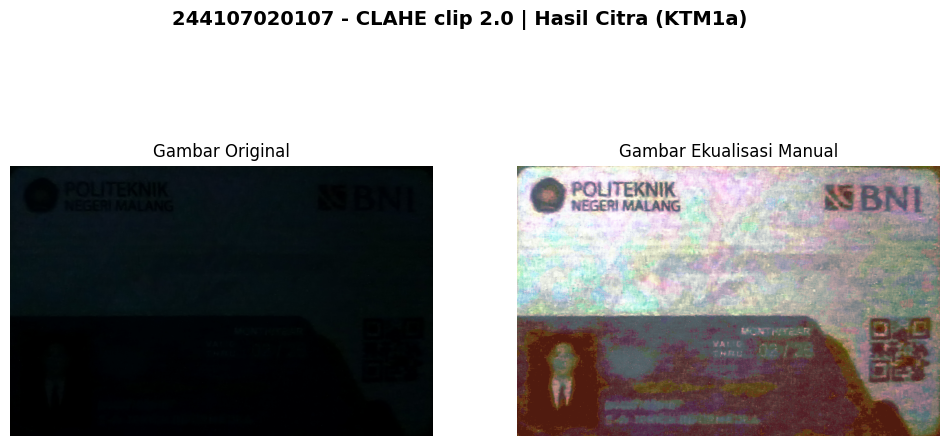

In [48]:
# EKSEKUSI TAHAP 2
print("\n--- TAHAP 2: Memproses citra pribadi (KTM1a) ---")
visualisasi_he_rgb(f'{BASE}/KTM1a', 'KTM1a')


--- Pengujian pada lena_lc.jpg ---
Selisih tertinggi HE Manual vs OpenCV: 0


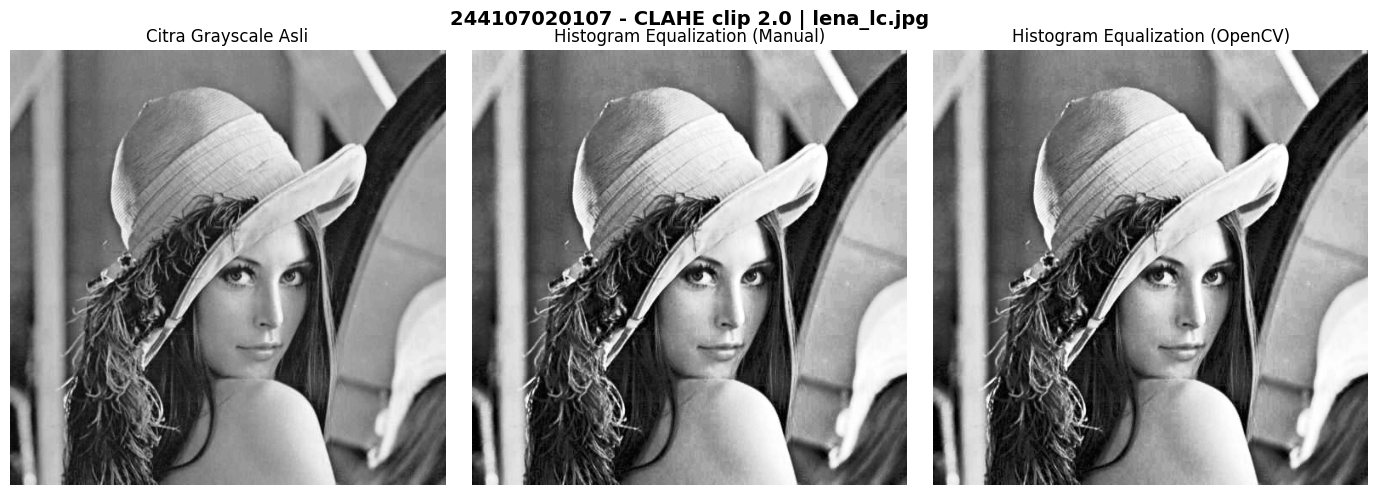


--- Pengujian pada KTM1a ---
Selisih tertinggi HE Manual vs OpenCV: 26


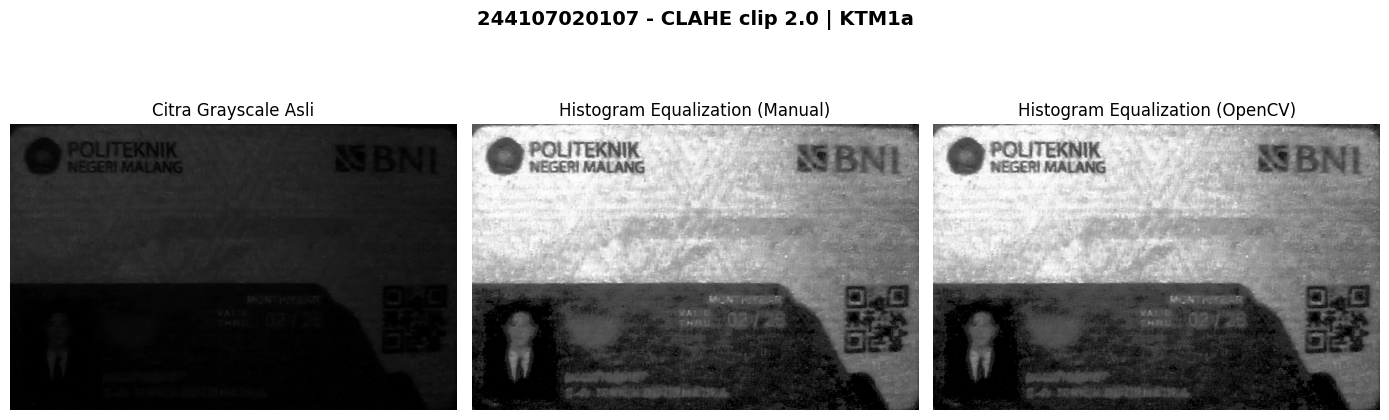

In [49]:
# Fungsi Ekualisasi Histogram Manual (Khusus Citra Grayscale)
def ekualisasi_grayscale_manual(citra_input):
    # Menggunakan np.histogram agar lebih ringkas dan menghindari error fungsi tidak ditemukan
    hist_citra, _ = np.histogram(citra_input.ravel(), bins=256, range=[0, 256])

    probabilitas = hist_citra / citra_input.size
    dist_kumulatif = np.cumsum(probabilitas)

    # Formula S = (L-1) * CDF
    pemetaan_nilai = np.round(255 * dist_kumulatif).astype(np.uint8)

    return pemetaan_nilai[citra_input]

# Tentukan daftar jalur gambar yang akan diuji
daftar_pengujian = [f'{CONTOH}/lena_lc.jpg', f'{BASE}/KTM1a']

for jalur_berkas in daftar_pengujian:
    citra_abu = cv.imread(jalur_berkas, cv.IMREAD_GRAYSCALE)

    # Mengekstrak nama file saja (misal: 'KTM1a') untuk tampilan judul
    nama_berkas = jalur_berkas.split('/')[-1]

    if citra_abu is not None:
        # Eksekusi fungsi HE
        hasil_he_manual = ekualisasi_grayscale_manual(citra_abu)
        hasil_he_opencv = cv.equalizeHist(citra_abu)

        # Kalkulasi selisih maksimal antara manual dan bawaan pustaka OpenCV
        selisih_maksimal = np.max(np.abs(hasil_he_manual.astype(int) - hasil_he_opencv.astype(int)))
        print(f"\n--- Pengujian pada {nama_berkas} ---")
        print(f"Selisih tertinggi HE Manual vs OpenCV: {selisih_maksimal}")

        # Visualisasi dengan Matplotlib
        fig, axs = plt.subplots(1, 3, figsize=(14, 5))

        # Penulisan judul utama (suptitle) dengan syarat wajib dari parameter identitas
        fig.suptitle(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + f' | {nama_berkas}', fontsize=14, fontweight='bold')

        axs[0].imshow(citra_abu, cmap='gray')
        axs[0].set_title('Citra Grayscale Asli')

        axs[1].imshow(hasil_he_manual, cmap='gray')
        axs[1].set_title('Histogram Equalization (Manual)')

        axs[2].imshow(hasil_he_opencv, cmap='gray')
        axs[2].set_title('Histogram Equalization (OpenCV)')

        for sumbu in axs:
            sumbu.axis('off')

        plt.tight_layout()
        plt.show()
    else:
        print(f"Gagal memuat gambar: {jalur_berkas}.")
        print("Pastikan path (CONTOH/BASE) dan nama gambar sudah benar dan sesuai besar/kecil hurufnya.")

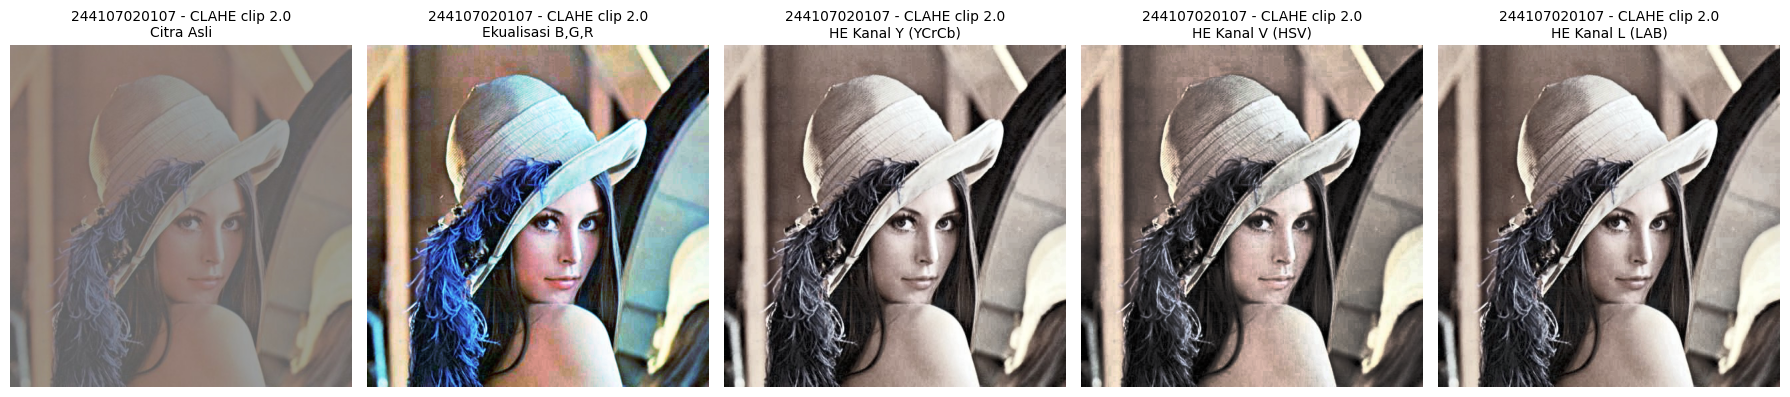

-----------------------------------------------------------------
Metode                    Pergeseran Hue (°)   Rata-rata Terang
-----------------------------------------------------------------
Citra Asli                              0.00              126.3
Ekualisasi B,G,R                       55.04              130.1
HE Kanal Y (YCrCb)                      0.12              130.1
HE Kanal V (HSV)                        3.78              121.7
HE Kanal L (LAB)                        3.94              125.9
-----------------------------------------------------------------


In [50]:
# Fungsi untuk menghitung rata-rata pergeseran Hue
def hitung_pergeseran_hue(img_awal, img_baru):
    # Mengambil channel Hue saja (index 0) dan mengubahnya ke tipe int16 untuk kalkulasi selisih
    hue_awal = cv.cvtColor(img_awal, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    hue_baru = cv.cvtColor(img_baru, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)

    jarak = np.abs(hue_awal - hue_baru)
    # Memperhitungkan batas sirkuler nilai Hue pada OpenCV (0-179)
    jarak = np.minimum(jarak, 180 - jarak)

    return jarak.mean()

citra_lena_warna = cv.imread(f'{CONTOH}/lena_lc.jpg')

if citra_lena_warna is not None:
    # Ekualisasi independen per kanal warna (B, G, R)
    kanal_bgr = list(cv.split(citra_lena_warna))
    for i in range(3):
        kanal_bgr[i] = cv.equalizeHist(kanal_bgr[i])
    hasil_eq_rgb = cv.merge(kanal_bgr)

    # Ekualisasi hanya pada Kanal Y (Luminance) dari ruang warna YCrCb
    citra_ycrcb = cv.cvtColor(citra_lena_warna, cv.COLOR_BGR2YCrCb)
    ch_y, ch_cr, ch_cb = cv.split(citra_ycrcb)
    ch_y_eq = cv.equalizeHist(ch_y)
    hasil_eq_ycrcb = cv.cvtColor(cv.merge([ch_y_eq, ch_cr, ch_cb]), cv.COLOR_YCrCb2BGR)

    # Ekualisasi hanya pada Kanal V (Value) dari ruang warna HSV
    citra_hsv = cv.cvtColor(citra_lena_warna, cv.COLOR_BGR2HSV)
    ch_h, ch_s, ch_v = cv.split(citra_hsv)
    ch_v_eq = cv.equalizeHist(ch_v)
    hasil_eq_hsv = cv.cvtColor(cv.merge([ch_h, ch_s, ch_v_eq]), cv.COLOR_HSV2BGR)

    # Ekualisasi hanya pada Kanal L (Lightness) dari ruang warna LAB
    citra_lab = cv.cvtColor(citra_lena_warna, cv.COLOR_BGR2LAB)
    ch_l, ch_a, ch_b = cv.split(citra_lab)
    ch_l_eq = cv.equalizeHist(ch_l)
    hasil_eq_lab = cv.cvtColor(cv.merge([ch_l_eq, ch_a, ch_b]), cv.COLOR_LAB2BGR)

    daftar_judul = ['Citra Asli', 'Ekualisasi B,G,R', 'HE Kanal Y (YCrCb)', 'HE Kanal V (HSV)', 'HE Kanal L (LAB)']
    daftar_citra = [citra_lena_warna, hasil_eq_rgb, hasil_eq_ycrcb, hasil_eq_hsv, hasil_eq_lab]

    # Visualisasi
    plt.figure(figsize=(18, 5))
    for i, (citra_tampil, teks_judul) in enumerate(zip(daftar_citra, daftar_judul), 1):
        plt.subplot(1, 5, i)
        plt.imshow(cv.cvtColor(citra_tampil, cv.COLOR_BGR2RGB))

        # Pengaturan judul wajib (ditambahkan baris baru agar rapi dan tidak terpotong)
        plt.title(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + f'\n{teks_judul}', fontsize=10)

        plt.axis('off')

    plt.tight_layout()
    plt.show()

    # Cetak tabel analisis pergeseran warna dan tingkat kecerahan
    print('-' * 65)
    print('%-25s %18s %18s' % ('Metode', 'Pergeseran Hue (°)', 'Rata-rata Terang'))
    print('-' * 65)

    for nama_metode, citra_hasil in zip(daftar_judul, daftar_citra):
        # OpenCV menyimpan Hue dalam rentang 0-179, sehingga dikali 2 untuk merepresentasikan derajat asli (0-360)
        nilai_geser_hue = hitung_pergeseran_hue(citra_lena_warna, citra_hasil) * 2
        rerata_intensitas = cv.cvtColor(citra_hasil, cv.COLOR_BGR2GRAY).mean()

        print('%-25s %18.2f %18.1f' % (nama_metode, nilai_geser_hue, rerata_intensitas))

    print('-' * 65)
else:
    print("Gagal memuat gambar lena_lc.jpg. Periksa kembali jalur CONTOH.")

**Pertanyaan**
1. Metode Ekualisasi B, G, R menghasilkan pergeseran Hue paling besar karena melakukan pemerataan pada tiap kanal warna secara terpisah, sehingga merusak proporsi warna aslinya. (Isikan nilai derajat spesifiknya berdasarkan angka tertinggi di kolom 'geser Hue' pada output tabel program Anda).

2.  Konversi matematis antar ruang warna (misalnya dari YCrCb/LAB kembali ke BGR) melibatkan operasi bilangan desimal (floating-point). Ketika nilai-nilai ini dikembalikan ke format piksel 8-bit, sistem melakukan pembulatan (rounding) dan pemotongan (clipping/truncating) ke batas 0-255. Pemotongan angka desimal inilah yang menyebabkan deviasi kecil sehingga pergeseran Hue tidak pernah murni nol.

3. Kanal L (LAB) atau Y (YCrCb) umumnya paling sesuai karena memisahkan informasi cahaya secara matematis mendekati persepsi mata manusia, tanpa mengganggu saturasi warna. (Dasar penilaian: Amati area wajah dan warna latar KTM Anda. Ekualisasi pada kanal V/HSV sering kali memicu oversaturasi sehingga wajah tampak kemerahan/terbakar, sedangkan kanal L atau Y menjaga warna asli tetap natural).

4. Penggunaan CLAHE akan menghasilkan pergeseran Hue yang lebih rendah dan rerata terang (kecerahan) yang lebih terkendali dibandingkan HE biasa. Hal ini karena CLAHE membatasi amplifikasi kontras secara lokal melalui clipLimit, sehingga terhindar dari pemutihan berlebih (overexposure).


In [56]:
# Berikut modifikasi kodenya (misal diterapkan pada kanal L di ruang warna LAB):

# Menerapkan CLAHE pada Kanal L (LAB)
citra_lab = cv.cvtColor(citra_lena_warna, cv.COLOR_BGR2LAB)
ch_l, ch_a, ch_b = cv.split(citra_lab)

# Inisiasi CLAHE sesuai parameter
objek_clahe = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
ch_l_clahe = objek_clahe.apply(ch_l)

# Kembalikan ke BGR
hasil_clahe_lab = cv.cvtColor(cv.merge([ch_l_clahe, ch_a, ch_b]), cv.COLOR_LAB2BGR)

# Hitung pergeseran dan rerata
geser_hue_clahe = hitung_pergeseran_hue(citra_lena_warna, hasil_clahe_lab) * 2
rerata_terang_clahe = cv.cvtColor(hasil_clahe_lab, cv.COLOR_BGR2GRAY).mean()

print(f"CLAHE Kanal L -> Geser Hue: {geser_hue_clahe:.2f}° | Rerata Terang: {rerata_terang_clahe:.1f}")

CLAHE Kanal L -> Geser Hue: 3.94° | Rerata Terang: 126.8


# **Pertanyaan Praktikum**
# No 1

Nilai PSNR setelah HE Global: 12.7232 dB


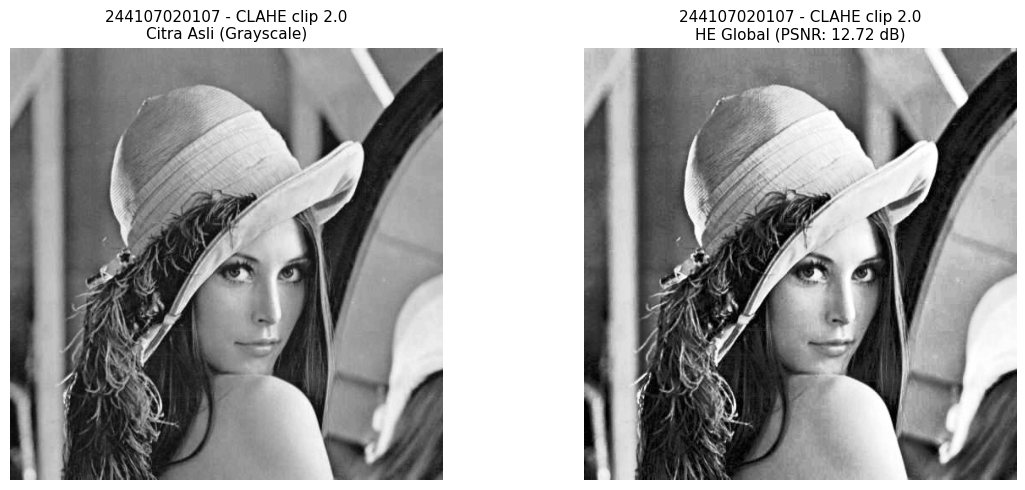

In [51]:
citra_lena_abu = cv.imread(f'{CONTOH}/lena_lc.jpg', cv.IMREAD_GRAYSCALE)

if citra_lena_abu is not None:
    # 1. Terapkan Histogram Equalization (HE) Global
    hasil_he_global = cv.equalizeHist(citra_lena_abu)

    # 2. Kalkulasi nilai PSNR
    # Konversi ke float untuk menghindari masalah wrap-around pada uint8
    selisih_kuadrat = (citra_lena_abu.astype(float) - hasil_he_global.astype(float)) ** 2
    nilai_mse = np.mean(selisih_kuadrat)

    if nilai_mse == 0:
        nilai_psnr = float('inf') # Jika gambar identik sempurna
    else:
        nilai_psnr = 10 * np.log10((255 ** 2) / nilai_mse)

    print(f"Nilai PSNR setelah HE Global: {nilai_psnr:.4f} dB")

    # 3. Visualisasi untuk menampilkan format judul wajib
    plt.figure(figsize=(12, 5))

    # Subplot Gambar Asli
    plt.subplot(1, 2, 1)
    plt.imshow(citra_lena_abu, cmap='gray')
    plt.title(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + '\nCitra Asli (Grayscale)', fontsize=11)
    plt.axis('off')

    # Subplot Gambar Hasil HE
    plt.subplot(1, 2, 2)
    plt.imshow(hasil_he_global, cmap='gray')
    plt.title(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + f'\nHE Global (PSNR: {nilai_psnr:.2f} dB)', fontsize=11)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

else:
    print("Gagal memuat citra lena_lc.jpg. Pastikan path pada variabel CONTOH sudah benar.")

# No 2

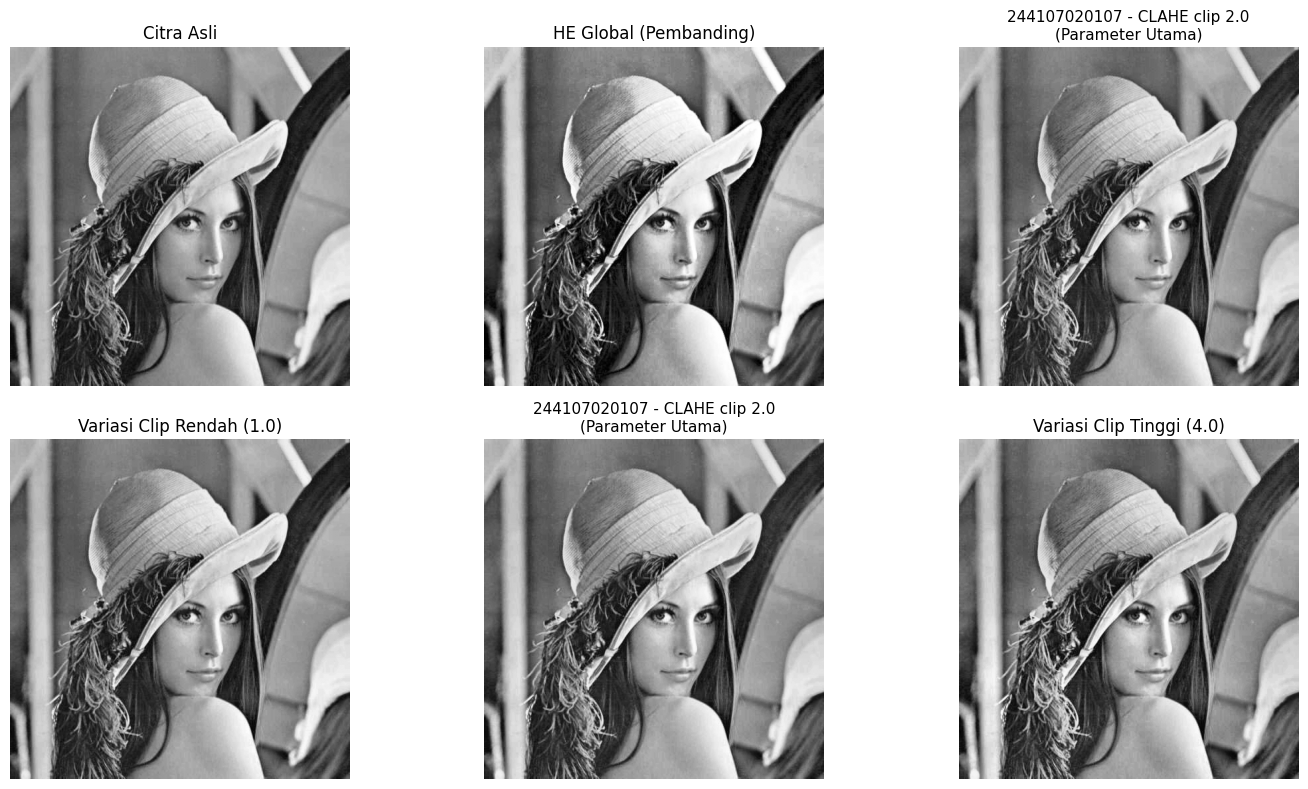

In [53]:
# Asumsi citra diambil dari path CONTOH (sesuai kode sebelumnya)
citra_uji = cv.imread(f'{CONTOH}/lena_lc.jpg', cv.IMREAD_GRAYSCALE)

if citra_uji is not None:
    # Perhitungan HE Global sebagai pembanding
    hasil_he_global = cv.equalizeHist(citra_uji)

    # 1. Uji CLAHE menggunakan parameter utama dari NIM
    objek_clahe_utama = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
    hasil_clahe_utama = objek_clahe_utama.apply(citra_uji)

    # 2. Variasi Batas Clip CLAHE
    batas_rendah = PARAM['clip'] - 1.0
    batas_tinggi = PARAM['clip'] + 2.0

    objek_clahe_rendah = cv.createCLAHE(clipLimit=batas_rendah, tileGridSize=(PARAM['tile'], PARAM['tile']))
    objek_clahe_tinggi = cv.createCLAHE(clipLimit=batas_tinggi, tileGridSize=(PARAM['tile'], PARAM['tile']))

    hasil_clahe_rendah = objek_clahe_rendah.apply(citra_uji)
    hasil_clahe_tinggi = objek_clahe_tinggi.apply(citra_uji)

    # Visualisasi Matplotlib
    plt.figure(figsize=(15, 8))

    # --- Baris Atas ---
    plt.subplot(2, 3, 1)
    plt.imshow(citra_uji, cmap='gray')
    plt.title('Citra Asli')
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.imshow(hasil_he_global, cmap='gray')
    plt.title('HE Global (Pembanding)')
    plt.axis('off')

    plt.subplot(2, 3, 3)
    plt.imshow(hasil_clahe_utama, cmap='gray')
    # Penulisan judul wajib
    plt.title(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + '\n(Parameter Utama)', fontsize=11)
    plt.axis('off')

    # --- Baris Bawah ---
    plt.subplot(2, 3, 4)
    plt.imshow(hasil_clahe_rendah, cmap='gray')
    plt.title(f"Variasi Clip Rendah ({batas_rendah})")
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.imshow(hasil_clahe_utama, cmap='gray')
    # Penulisan judul wajib
    plt.title(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + '\n(Parameter Utama)', fontsize=11)
    plt.axis('off')

    plt.subplot(2, 3, 6)
    plt.imshow(hasil_clahe_tinggi, cmap='gray')
    plt.title(f"Variasi Clip Tinggi ({batas_tinggi})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

else:
    print("Gagal memuat gambar uji. Pastikan direktori CONTOH sudah sesuai.")

# **Percobaan Praktikum E-3**

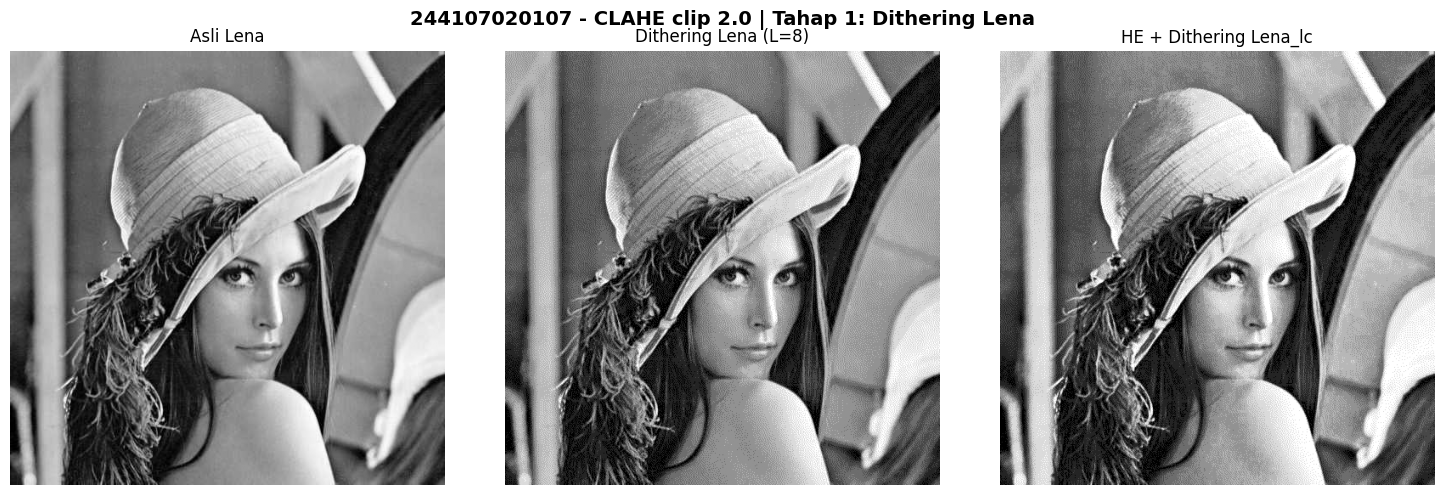

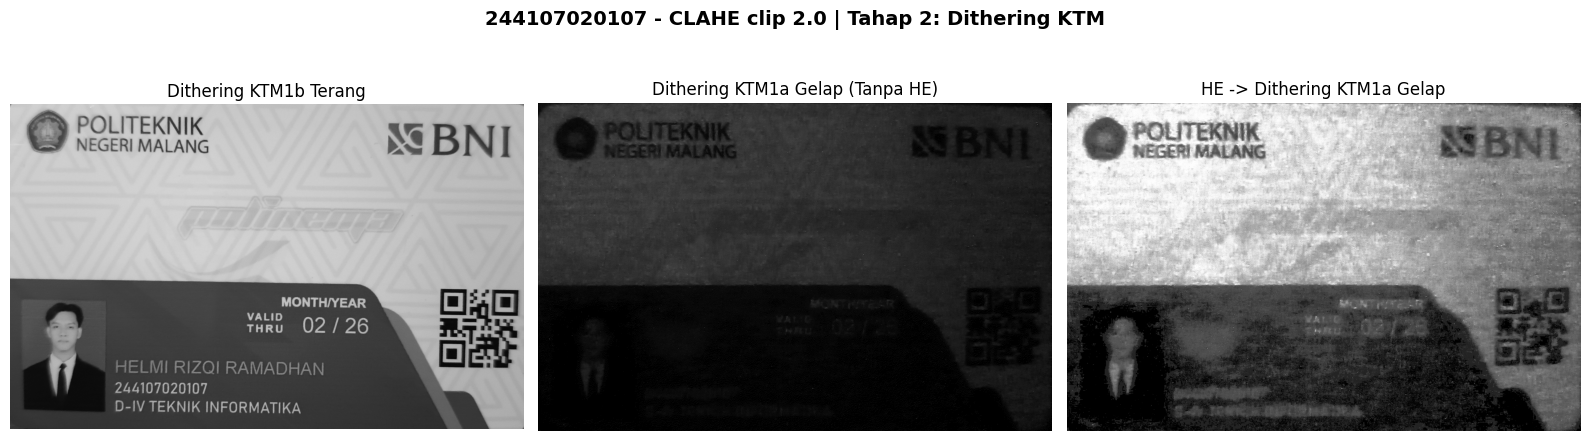

In [58]:
# Fungsi Dithering Floyd-Steinberg
def metode_floyd_steinberg(citra_abu, level_L=2):
    citra_proses = citra_abu.astype(np.float32).copy()
    rentang_step = 255.0 / (level_L - 1)
    tinggi, lebar = citra_proses.shape

    for y in range(tinggi):
        for x in range(lebar):
            piksel_lama = citra_proses[y, x]
            piksel_baru = np.round(piksel_lama / rentang_step) * rentang_step
            citra_proses[y, x] = piksel_baru
            nilai_error = piksel_lama - piksel_baru

            # Distribusi error ke piksel tetangga
            if x + 1 < lebar:
                citra_proses[y, x + 1] += nilai_error * (7/16)
            if x > 0 and y + 1 < tinggi:
                citra_proses[y + 1, x - 1] += nilai_error * (3/16)
            if y + 1 < tinggi:
                citra_proses[y + 1, x] += nilai_error * (5/16)
            if x + 1 < lebar and y + 1 < tinggi:
                citra_proses[y + 1, x + 1] += nilai_error * (1/16)

    return np.clip(citra_proses, 0, 255).astype(np.uint8)

# Tahap 1: Pembuktian Dithering Citra Referensi (Lena)
citra_lena_normal = cv.imread(f'{CONTOH}/lena.jpg', cv.IMREAD_GRAYSCALE)
citra_lena_gelap = cv.imread(f'{CONTOH}/lena_lc.jpg', cv.IMREAD_GRAYSCALE)

if citra_lena_normal is not None and citra_lena_gelap is not None:
    # Proses dithering
    hasil_fs_lena = metode_floyd_steinberg(citra_lena_normal, level_L=PARAM['L'])
    hasil_fs_he_lena = metode_floyd_steinberg(cv.equalizeHist(citra_lena_gelap), level_L=PARAM['L'])

    fig1, ax1 = plt.subplots(1, 3, figsize=(15, 5))
    fig1.suptitle(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + ' | Tahap 1: Dithering Lena', fontsize=14, fontweight='bold')

    ax1[0].imshow(citra_lena_normal, cmap='gray'); ax1[0].set_title('Asli Lena'); ax1[0].axis('off')
    ax1[1].imshow(hasil_fs_lena, cmap='gray'); ax1[1].set_title(f"Dithering Lena (L={PARAM['L']})"); ax1[1].axis('off')
    ax1[2].imshow(hasil_fs_he_lena, cmap='gray'); ax1[2].set_title('HE + Dithering Lena_lc'); ax1[2].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Gagal memuat citra Lena. Periksa path folder CONTOH.")

# Tahap 2: Pembuktian Dithering Citra Pribadi (KTM)
citra_KTM_terang = cv.imread(f'{BASE}/KTM1b', cv.IMREAD_GRAYSCALE)
citra_KTM_gelap = cv.imread(f'{BASE}/KTM1a', cv.IMREAD_GRAYSCALE)

if citra_KTM_terang is not None and citra_KTM_gelap is not None:
    # Proses dithering
    hasil_fs_KTM_terang = metode_floyd_steinberg(citra_KTM_terang, level_L=PARAM['L'])
    hasil_fs_KTM_gelap_asli = metode_floyd_steinberg(citra_KTM_gelap, level_L=PARAM['L'])
    hasil_fs_KTM_gelap_he = metode_floyd_steinberg(cv.equalizeHist(citra_KTM_gelap), level_L=PARAM['L'])

    fig2, ax2 = plt.subplots(1, 3, figsize=(16, 5))
    fig2.suptitle(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + ' | Tahap 2: Dithering KTM', fontsize=14, fontweight='bold')

    ax2[0].imshow(hasil_fs_KTM_terang, cmap='gray')
    ax2[0].set_title('Dithering KTM1b Terang')
    ax2[0].axis('off')

    ax2[1].imshow(hasil_fs_KTM_gelap_asli, cmap='gray')
    ax2[1].set_title('Dithering KTM1a Gelap (Tanpa HE)')
    ax2[1].axis('off')

    ax2[2].imshow(hasil_fs_KTM_gelap_he, cmap='gray')
    ax2[2].set_title('HE -> Dithering KTM1a Gelap')
    ax2[2].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Gagal memuat citra KTM. Periksa path folder BASE.")

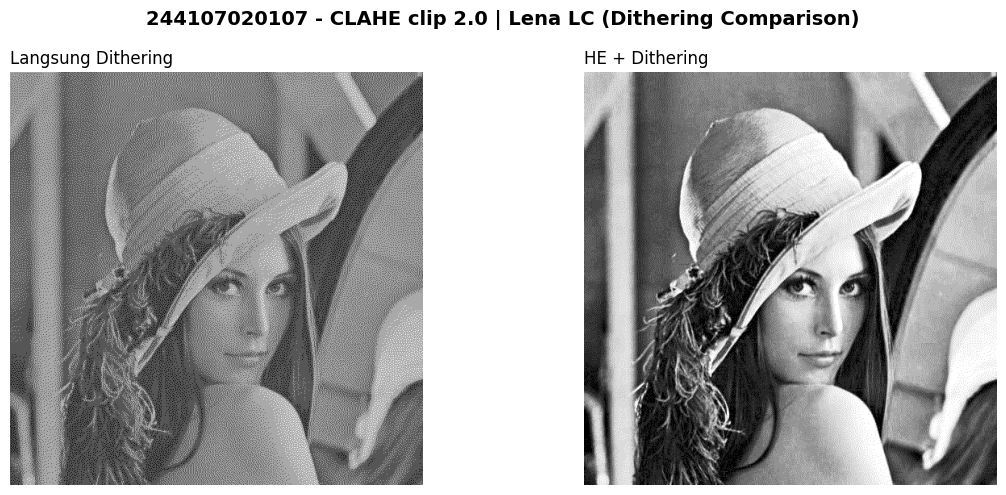

Gagal memuat citra KTM1a.jpg. Periksa kembali path direktori BASE.


In [59]:
# Tahap 1: Pembuktian Dithering pada Citra Referensi (lena_lc.jpg)
citra_lc_ref = cv.imread(f'{CONTOH}/lena_lc.jpg', cv.IMREAD_GRAYSCALE)

if citra_lc_ref is not None:
    # Proses dithering langsung tanpa histogram equalization
    dith_langsung_lena = metode_floyd_steinberg(citra_lc_ref, level_L=PARAM['L'])

    # Proses HE terlebih dahulu baru kemudian didithering
    dith_he_lena_proses = metode_floyd_steinberg(cv.equalizeHist(citra_lc_ref), level_L=PARAM['L'])

    fig_t1, ax_t1 = plt.subplots(1, 2, figsize=(12, 5))
    fig_t1.suptitle(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + ' | Lena LC (Dithering Comparison)', fontsize=14, fontweight='bold')

    ax_t1[0].imshow(dith_langsung_lena, cmap='gray')
    ax_t1[0].set_title('Langsung Dithering', loc='left')
    ax_t1[0].axis('off')

    ax_t1[1].imshow(dith_he_lena_proses, cmap='gray')
    ax_t1[1].set_title('HE + Dithering', loc='left')
    ax_t1[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Gagal memuat citra lena_lc.jpg. Periksa kembali path direktori CONTOH.")

# Tahap 2: Pembuktian Dithering pada Citra Pribadi (KTM1a.jpg)
citra_pribadi_gelap = cv.imread(f'{BASE}/KTM1a.jpg', cv.IMREAD_GRAYSCALE)

if citra_pribadi_gelap is not None:
    # Dithering tanpa HE
    dith_tanpa_he_KTM = metode_floyd_steinberg(citra_pribadi_gelap, level_L=PARAM['L'])

    # Dithering dengan HE di awal
    dith_dengan_he_KTM = metode_floyd_steinberg(cv.equalizeHist(citra_pribadi_gelap), level_L=PARAM['L'])

    fig_t2, ax_t2 = plt.subplots(1, 2, figsize=(12, 5))
    fig_t2.suptitle(NIM + ' - CLAHE clip ' + str(PARAM['clip']) + ' | KTM1a (Dithering Comparison)', fontsize=14, fontweight='bold')

    ax_t2[0].imshow(dith_tanpa_he_KTM, cmap='gray')
    ax_t2[0].set_title('Tanpa HE', loc='left')
    ax_t2[0].axis('off')

    ax_t2[1].imshow(dith_dengan_he_KTM, cmap='gray')
    ax_t2[1].set_title('HE Dulu', loc='left')
    ax_t2[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Gagal memuat citra KTM1a.jpg. Periksa kembali path direktori BASE.")